# Practical No. 7 — Apply LSTM to Predict Stock Prices from Historical Data

## Aim
To implement a Long Short-Term Memory (LSTM) neural network for predicting future stock prices using historical stock market data.

## Objectives
- To understand time-series forecasting.
- To preprocess stock market data.
- To build an LSTM model for stock price prediction.
- To train and evaluate the model.
- To visualize actual and predicted stock prices.

## Theory
### Stock Price Prediction
Stock Price Prediction involves forecasting future stock values using historical stock market data such as **Open Price**, **High Price**, **Low Price**, **Close Price**, and **Volume**. Time-series forecasting helps investors analyze market trends and make informed decisions.

### What is LSTM?
LSTM (Long Short-Term Memory) is a special type of Recurrent Neural Network (RNN) designed to learn long-term dependencies in sequential data. Unlike traditional RNNs, LSTMs can remember important information for longer periods and avoid the vanishing gradient problem.

**Components:** Forget Gate, Input Gate, Cell State, Output Gate. These gates control information flow through the network.

**Why LSTM for stock prediction?** Handles sequential data efficiently; captures long-term market trends; learns temporal dependencies; provides better forecasting than traditional RNNs.

## Dataset
The Word document lists Yahoo Finance, NSE India, BSE India, and Kaggle Datasets as possible sources for historical stock data. The experiment reads **`stock_data.csv`** and uses its **`Close`** column.

**Sample dataset shown in the document (illustrative only):**

| Date | Open | High | Low | Close | Volume |
|---|---:|---:|---:|---:|---:|
| 01-01-2024 | 120 | 125 | 118 | 123 | 500000 |
| 02-01-2024 | 123 | 128 | 122 | 127 | 650000 |

The two sample rows alone are **not sufficient** for 60-step sequences. Upload a historical `stock_data.csv` containing **more than 61 records**, with a numeric `Close` column, before running the notebook. No real dataset was attached, so none is invented here.

## Software Requirements
- Python 3.x
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Scikit-Learn
- Google Colab / Jupyter Notebook (execution environment)

Google Colab usually has these installed. If an import fails, uncomment and run the following installation cell.

In [1]:
# Uncomment only if packages are missing in Google Colab.
# %pip install numpy pandas matplotlib scikit-learn tensorflow

## Algorithm
1. Load historical stock data.
2. Select Closing Price column.
3. Normalize the data.
4. Create time-series sequences.
5. Split into training and testing datasets.
6. Build LSTM architecture.
7. Train the model.
8. Predict stock prices.
9. Evaluate performance.
10. Plot actual vs predicted prices.

## Mathematical Representation
The hidden state is updated based on previous information:

\[h_t=f(h_{t-1},x_t)\]

where \(x_t\) = current input, \(h_t\) = hidden state, \(h_{t-1}\) = previous hidden state.

## Program — Step 1: Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

## Step 2: Load Dataset
In Google Colab, select **Files** in the left sidebar and upload `stock_data.csv`, or run the upload cell below. Use the file name given in the Word document.

In [6]:
from pathlib import Path
import pandas as pd

# Windows-compatible path
BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "dataset" / "Book1.csv"

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {CSV_PATH}")

# Load dataset
data = pd.read_csv(CSV_PATH)

print("Dataset Loaded Successfully!")
print("\nColumns:", data.columns.tolist())
print("\nFirst 5 Rows:")
print(data.head())

# Use the actual column from your CSV
if "Close" in data.columns:
    TARGET_COLUMN = "Close"
elif "Closing Volume" in data.columns:
    TARGET_COLUMN = "Closing Volume"
    print("\nWarning: Using 'Closing Volume' instead of 'Close'.")
else:
    raise ValueError("Neither 'Close' nor 'Closing Volume' exists.")

data[TARGET_COLUMN] = pd.to_numeric(
    data[TARGET_COLUMN], errors="coerce"
)

data = data.dropna(subset=[TARGET_COLUMN]).reset_index(drop=True)

print("\nSelected column:", TARGET_COLUMN)
print("Total records:", len(data))

Dataset Loaded Successfully!

Columns: ['Date', 'Closing Volume', 'Volume', '50-Day Moving Average', '200-Day Moving Average']

First 5 Rows:
       Date  Closing Volume        Volume  50-Day Moving Average  \
0  01-01-20        6.698408  295689.37230              55.356753   
1  02-01-20       61.452089  847607.11960              56.107148   
2  03-01-20       21.911287  804114.07660              55.246507   
3  04-01-20       47.445713  844474.63390              56.443637   
4  05-01-20       88.814258   36360.73427              57.048413   

   200-Day Moving Average  
0               54.001058  
1               54.034503  
2               54.222753  
3               54.207440  
4               53.992278  


Selected column: Closing Volume
Total records: 2500


## Step 3: Select Closing Price

In [10]:
dataset = data[TARGET_COLUMN].values
dataset = dataset.reshape(-1, 1)

print("Dataset shape:", dataset.shape)

Dataset shape: (2500, 1)


## Step 4: Normalize Data

In [11]:
scaler = MinMaxScaler(feature_range=(0, 1))
dataset_scaled = scaler.fit_transform(dataset)
print('Scaled data shape:', dataset_scaled.shape)

Scaled data shape: (2500, 1)


## Step 5: Create Sequences

In [12]:
X = []
y = []
for i in range(60, len(dataset_scaled)):
    X.append(dataset_scaled[i-60:i, 0])
    y.append(dataset_scaled[i, 0])
X = np.array(X)
y = np.array(y)
X = np.reshape(X, (X.shape[0], X.shape[1], 1))
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (2440, 60, 1) | y shape: (2440,)


## Step 6: Split Dataset

In [13]:
train_size = int(len(X) * 0.8)
X_train = X[:train_size]
y_train = y[:train_size]
X_test = X[train_size:]
y_test = y[train_size:]
print('Training samples:', len(X_train), '| Testing samples:', len(X_test))

Training samples: 1952 | Testing samples: 488


## Step 7: Build LSTM Model

In [14]:
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(LSTM(units=50))
model.add(Dense(25))
model.add(Dense(1))

c:\Users\shree\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Step 8: Compile Model

In [15]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

## Step 9: Train Model

In [16]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32
)

Epoch 1/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0990
Epoch 2/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0875
Epoch 3/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0871
Epoch 4/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0868
Epoch 5/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0866
Epoch 6/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0865
Epoch 7/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0864
Epoch 8/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0863
Epoch 9/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0862
Epoch 10/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0862
Epoch 11/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0861
Epoch 12/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0861
Epoch 13/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0861
Epoch 14/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0861
Epoch 15/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0860
Epoc

## Step 10: Predict Stock Prices

In [17]:
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)
print('Predictions shape:', predictions.shape)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
Predictions shape: (488, 1)


## Step 11: Evaluate Model

In [18]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(
    scaler.inverse_transform(y_test.reshape(-1, 1)),
    predictions
))
print('RMSE:', rmse)

RMSE: 29.260633593437205


## Step 12: Visualization

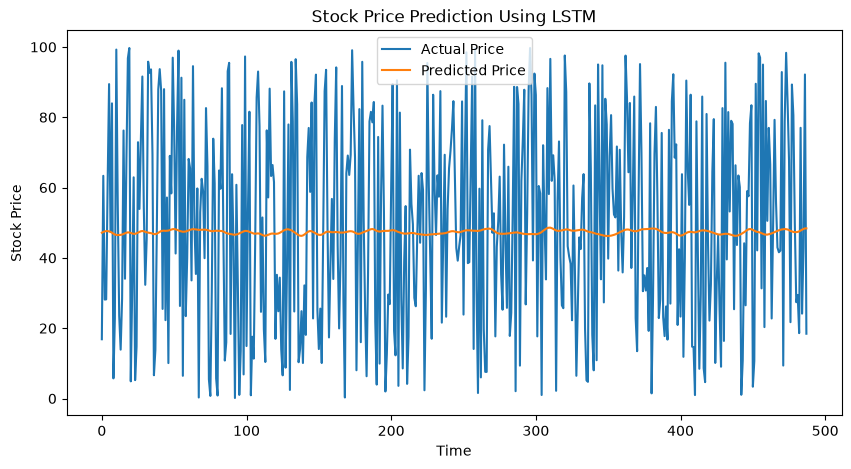

In [19]:
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))
plt.figure(figsize=(10, 5))
plt.plot(actual_prices, label='Actual Price')
plt.plot(predictions, label='Predicted Price')
plt.title('Stock Price Prediction Using LSTM')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

## Result (from Word document)
An LSTM-based deep learning model was successfully implemented to predict stock prices from historical data. The model learned temporal patterns from previous stock prices and generated future price predictions with low prediction error.

*Run Steps 1–12 with your own `stock_data.csv` to confirm the result for your dataset.*